# Titanic Survival Prediction

## Project Overview

This project uses the Titanic dataset to predict whether a passenger survived the Titanic disaster.

The project follows a complete machine learning workflow:

- Data exploration
- Data visualization
- Data preprocessing
- Feature engineering
- Train-test splitting
- Machine learning model training
- Model evaluation
- 5-fold cross-validation
- Model comparison

The following machine learning models are evaluated:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree
4. Support Vector Machine (SVM)
5. Random Forest

The goal is to understand how different machine learning algorithms perform on the same classification problem and compare their results using consistent evaluation methods.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("data/train.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Exploratory Data Analysis

Before building machine learning models, we first examine the dataset's structure, data types, missing values, and basic statistics.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

## 3. Data Visualization

Visualizations help us understand patterns and relationships between passenger characteristics and survival.

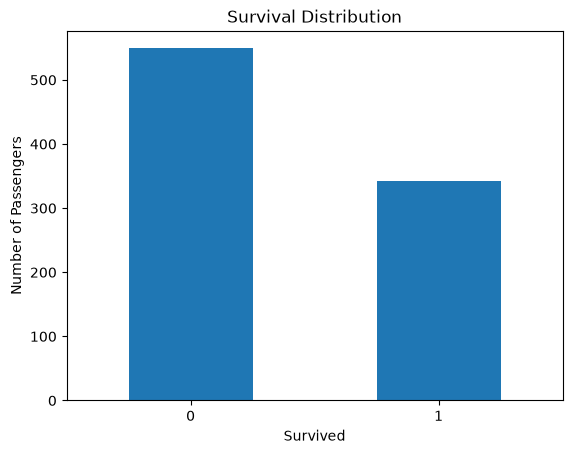

In [6]:
df["Survived"].value_counts().plot(kind="bar")

plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

plt.show()

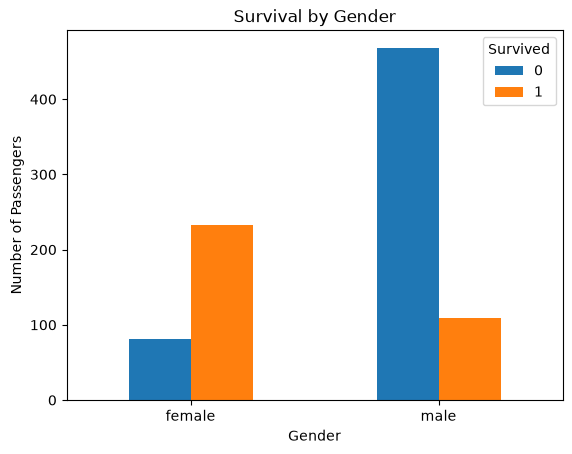

In [7]:
pd.crosstab(df["Sex"], df["Survived"]).plot(kind="bar")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

plt.show()

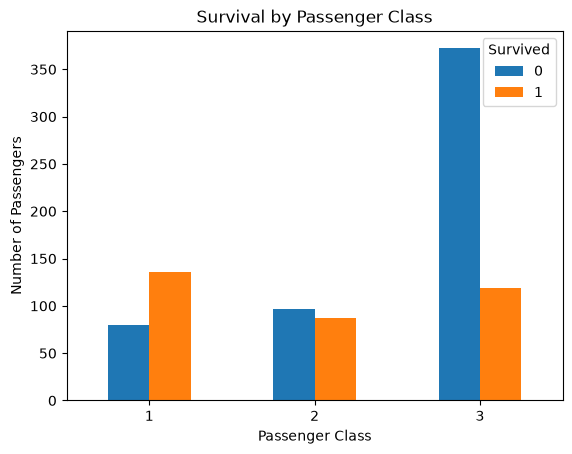

In [8]:
pd.crosstab(df["Pclass"], df["Survived"]).plot(kind="bar")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

plt.show()

## 4. Feature Selection

We separate the target variable from the input features.

The target variable is `Survived`, while the selected features are `Pclass`, `Age`, `Fare`, `Sex`, and `Embarked`.

Identifiers and high-cardinality or highly incomplete columns such as `PassengerId`, `Name`, `Ticket`, and `Cabin` are excluded from the initial modeling process.

In [9]:
X = df[["Pclass", "Age", "Fare", "Sex", "Embarked"]]

y = df["Survived"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Pclass   Age     Fare     Sex Embarked
0       3  22.0   7.2500    male        S
1       1  38.0  71.2833  female        C
2       3  26.0   7.9250  female        S
3       1  35.0  53.1000  female        S
4       3  35.0   8.0500    male        S

Target:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


## 5. Data Preprocessing

Before training the models, we split the dataset into training and testing sets.

The preprocessing pipeline handles:

- Missing numerical values using median imputation
- Numerical feature scaling using `StandardScaler`
- Categorical feature encoding using `OneHotEncoder`

The preprocessing is fitted only on the training data through the pipeline, helping prevent data leakage.

In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 712
Testing samples: 179


### Numerical and Categorical Features

Numerical features require numerical preprocessing, while categorical features need to be encoded before they can be used by most machine learning models.

In [11]:
numerical_features = ["Pclass", "Age", "Fare"]
categorical_features = ["Sex", "Embarked"]

### Preprocessing Pipeline

We use a `ColumnTransformer` to apply different preprocessing steps to numerical and categorical features.

In [12]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [13]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Processed training shape:", X_train_processed.shape)

Processed training shape: (712, 6)


In [14]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__Pclass' 'num__Age' 'num__Fare' 'cat__Sex_male' 'cat__Embarked_Q'
 'cat__Embarked_S']


## 6. Machine Learning Models

### 6.1 Logistic Regression

Logistic Regression is a classification algorithm that estimates the probability of an observation belonging to a particular class.

We use a pipeline so that preprocessing is performed as part of the model training process.

In [15]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train);

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [16]:
y_pred_logistic = logistic_model.predict(X_test)

print(y_pred_logistic[:10])

[0 0 0 0 1 0 1 0 0 0]


In [43]:
print("Accuracy:", accuracy_score(y_test, y_pred_logistic))
print("Precision:", precision_score(y_test, y_pred_logistic))
print("Recall:", recall_score(y_test, y_pred_logistic))
print("F1 Score:", f1_score(y_test, y_pred_logistic))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

Accuracy: 0.770949720670391
Precision: 0.71875
Recall: 0.6666666666666666
F1 Score: 0.6917293233082706

Confusion Matrix:
[[92 18]
 [23 46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       110
           1       0.72      0.67      0.69        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179



### 6.2 K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) classifies a data point based on the classes of nearby observations.

Because KNN relies on distances between observations, numerical features need to be scaled before training.

In [18]:
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=7))
])

knn_model.fit(X_train, y_train);

print("KNN model trained successfully.")

KNN model trained successfully.


In [19]:
y_pred_knn = knn_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_knn[:10])

First 10 predictions:
[0 0 0 0 1 0 1 0 1 0]


In [20]:
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("F1 Score:", f1_score(y_test, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

Accuracy: 0.7877094972067039
Precision: 0.7627118644067796
Recall: 0.6521739130434783
F1 Score: 0.703125

Confusion Matrix:
[[96 14]
 [24 45]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.87      0.83       110
           1       0.76      0.65      0.70        69

    accuracy                           0.79       179
   macro avg       0.78      0.76      0.77       179
weighted avg       0.79      0.79      0.78       179



### 6.3 Decision Tree

A Decision Tree makes predictions by repeatedly splitting the data based on feature values.

Unlike distance-based models such as KNN, Decision Trees do not require feature scaling.

In [21]:
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

decision_tree_model.fit(X_train, y_train);

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [22]:
y_pred_tree = decision_tree_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_tree[:10])

First 10 predictions:
[0 0 0 0 1 0 1 1 0 0]


In [23]:
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1 Score:", f1_score(y_test, y_pred_tree))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

Accuracy: 0.8156424581005587
Precision: 0.7727272727272727
Recall: 0.7391304347826086
F1 Score: 0.7555555555555555

Confusion Matrix:
[[95 15]
 [18 51]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       110
           1       0.77      0.74      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



### 6.4 Support Vector Machine (SVM)

Support Vector Machine (SVM) is a classification algorithm that attempts to find a decision boundary that separates different classes.

SVM is sensitive to feature scale, so the numerical features are standardized as part of the preprocessing pipeline.

In [24]:
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(C=1, kernel="rbf"))
])

svm_model.fit(X_train, y_train);

print("SVM model trained successfully.")

SVM model trained successfully.


In [25]:
y_pred_svm = svm_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_svm[:10])

First 10 predictions:
[0 0 0 0 1 0 1 0 0 0]


In [26]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

Accuracy: 0.8100558659217877
Precision: 0.8723404255319149
Recall: 0.5942028985507246
F1 Score: 0.7068965517241379

Confusion Matrix:
[[104   6]
 [ 28  41]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.95      0.86       110
           1       0.87      0.59      0.71        69

    accuracy                           0.81       179
   macro avg       0.83      0.77      0.78       179
weighted avg       0.82      0.81      0.80       179



### 6.5 Random Forest

Random Forest is an ensemble learning method that combines multiple Decision Trees.

Each tree learns from a different sample of the training data and considers subsets of features. The final prediction is based on the combined predictions of the trees.

In [27]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

random_forest_model.fit(X_train, y_train);

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [28]:
y_pred_rf = random_forest_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_rf[:10])

First 10 predictions:
[0 0 0 0 1 0 1 1 1 0]


In [29]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8156424581005587
Precision: 0.78125
Recall: 0.7246376811594203
F1 Score: 0.7518796992481203

Confusion Matrix:
[[96 14]
 [19 50]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



## 7. Cross-Validation

A single train-test split gives us only one estimate of model performance.

To obtain a more reliable comparison, we use 5-fold cross-validation.

The dataset is divided into five parts. Each model is trained on four folds and evaluated on the remaining fold. This process is repeated five times so that every observation is used for validation once.

We compare the models using mean accuracy and standard deviation across the five folds.

In [30]:
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Decision Tree": decision_tree_model,
    "SVM": svm_model,
    "Random Forest": random_forest_model
}

In [31]:
cv_results = {}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )
    
    cv_results[name] = scores
    
    print(name)
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean())
    print("Standard deviation:", scores.std())
    print()

Logistic Regression
Fold scores: [0.78212291 0.78651685 0.78651685 0.76966292 0.79213483]
Mean accuracy: 0.7833908731404181
Standard deviation: 0.007563923882125692

KNN
Fold scores: [0.77653631 0.7752809  0.83146067 0.79775281 0.83707865]
Mean accuracy: 0.8036218693114054
Standard deviation: 0.02632732111402964

Decision Tree
Fold scores: [0.74860335 0.79213483 0.80337079 0.76404494 0.8258427 ]
Mean accuracy: 0.7867993220764548
Standard deviation: 0.027583183477904446



SVM
Fold scores: [0.81564246 0.83146067 0.84831461 0.79213483 0.84831461]
Mean accuracy: 0.8271734354403364
Standard deviation: 0.021321096927910566

Random Forest
Fold scores: [0.7877095  0.80898876 0.83707865 0.78651685 0.83146067]
Mean accuracy: 0.8103508882053857
Standard deviation: 0.021178033723080764



### Cross-Validation Results

The mean accuracy represents the average performance across the five folds.

The standard deviation shows how much the model's performance varies between folds.

In [32]:
cv_summary = pd.DataFrame({
    "Model": list(cv_results.keys()),
    "Mean Accuracy": [scores.mean() for scores in cv_results.values()],
    "Standard Deviation": [scores.std() for scores in cv_results.values()]
})

cv_summary

,Model,Mean Accuracy,Standard Deviation
0,Logistic Regression,0.783391,0.007564
1,KNN,0.803622,0.026327
2,Decision Tree,0.786799,0.027583
3,SVM,0.827173,0.021321
4,Random Forest,0.810351,0.021178


### Model Comparison

The following chart compares the mean 5-fold cross-validation accuracy of the five machine learning models.

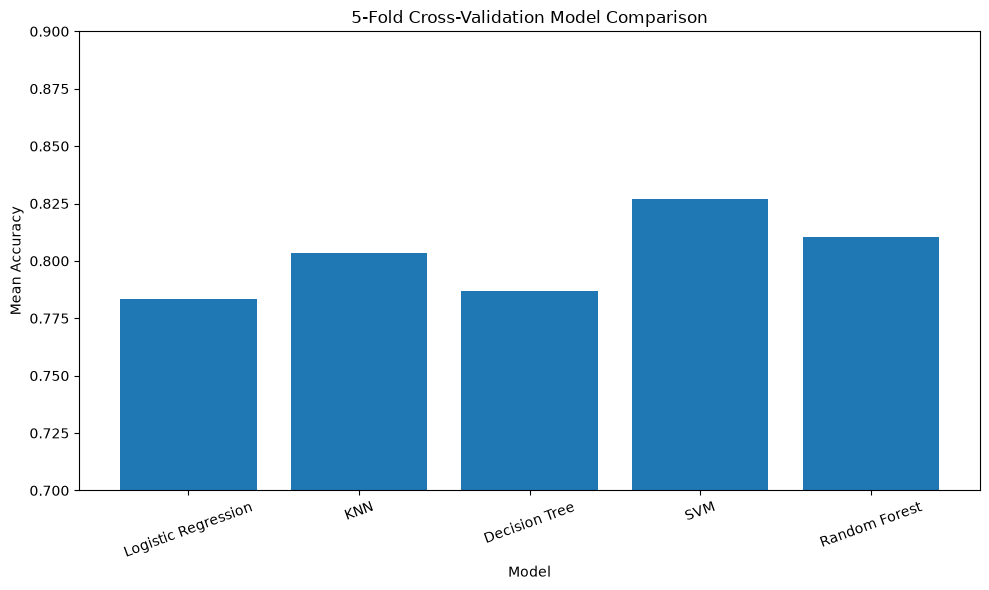

In [33]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_summary["Model"],
    cv_summary["Mean Accuracy"]
)

plt.title("5-Fold Cross-Validation Model Comparison")
plt.xlabel("Model")
plt.ylabel("Mean Accuracy")

plt.ylim(0.7, 0.9)
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig("images/cv_model_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

## 8. Hyperparameter Tuning

The performance of a machine learning model can depend on its hyperparameters.

For the SVM model, we will tune:

- `C`: controls the trade-off between a wider margin and classification errors
- `gamma`: controls how strongly each training example influences the decision boundary
- `kernel`: determines the type of decision boundary used by the SVM

We use `GridSearchCV` to evaluate different combinations of these hyperparameters using cross-validation.

In [34]:
param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", "auto"],
    "model__kernel": ["rbf", "linear"]
}

In [35]:
svm_grid = GridSearchCV(
    svm_model,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

In [36]:
svm_grid.fit(X, y);

print("SVM hyperparameter tuning completed.")

SVM hyperparameter tuning completed.


In [37]:
print("Best parameters:")
print(svm_grid.best_params_)

print("\nBest cross-validation accuracy:")
print(svm_grid.best_score_)

Best parameters:
{'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}

Best cross-validation accuracy:
0.8271734354403364


## 9. Final Model Evaluation

After hyperparameter tuning, we evaluate the tuned SVM on the held-out test set.

The test set provides an independent estimate of how the final model performs on unseen data.

In [38]:
best_svm = svm_grid.best_estimator_

y_pred_best_svm = best_svm.predict(X_test)

In [39]:
print("Accuracy:", accuracy_score(y_test, y_pred_best_svm))
print("Precision:", precision_score(y_test, y_pred_best_svm))
print("Recall:", recall_score(y_test, y_pred_best_svm))
print("F1 Score:", f1_score(y_test, y_pred_best_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best_svm))

Accuracy: 0.8100558659217877
Precision: 0.8723404255319149
Recall: 0.5942028985507246
F1 Score: 0.7068965517241379

Confusion Matrix:
[[104   6]
 [ 28  41]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.95      0.86       110
           1       0.87      0.59      0.71        69

    accuracy                           0.81       179
   macro avg       0.83      0.77      0.78       179
weighted avg       0.82      0.81      0.80       179



## 10. Final Model Comparison

The models are compared using their test-set performance and 5-fold cross-validation results.

Cross-validation provides a more reliable estimate of generalization performance than relying on a single train-test split.

In [40]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "SVM",
        "Random Forest"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_best_svm),
        accuracy_score(y_test, y_pred_rf)
    ],
    "CV Mean Accuracy": [
        cv_results["Logistic Regression"].mean(),
        cv_results["KNN"].mean(),
        cv_results["Decision Tree"].mean(),
        cv_results["SVM"].mean(),
        cv_results["Random Forest"].mean()
    ],
    "CV Std": [
        cv_results["Logistic Regression"].std(),
        cv_results["KNN"].std(),
        cv_results["Decision Tree"].std(),
        cv_results["SVM"].std(),
        cv_results["Random Forest"].std()
    ]
})

final_comparison.round(4).style.hide(axis="index")

Model,Test Accuracy,CV Mean Accuracy,CV Std
Logistic Regression,0.770900,0.783400,0.007600
KNN,0.787700,0.803600,0.026300
Decision Tree,0.815600,0.786800,0.027600
SVM,0.810100,0.827200,0.021300
Random Forest,0.815600,0.810400,0.021200


### Test Accuracy vs Cross-Validation Accuracy

This chart compares each model's accuracy on the held-out test set with its mean accuracy across the five cross-validation folds.

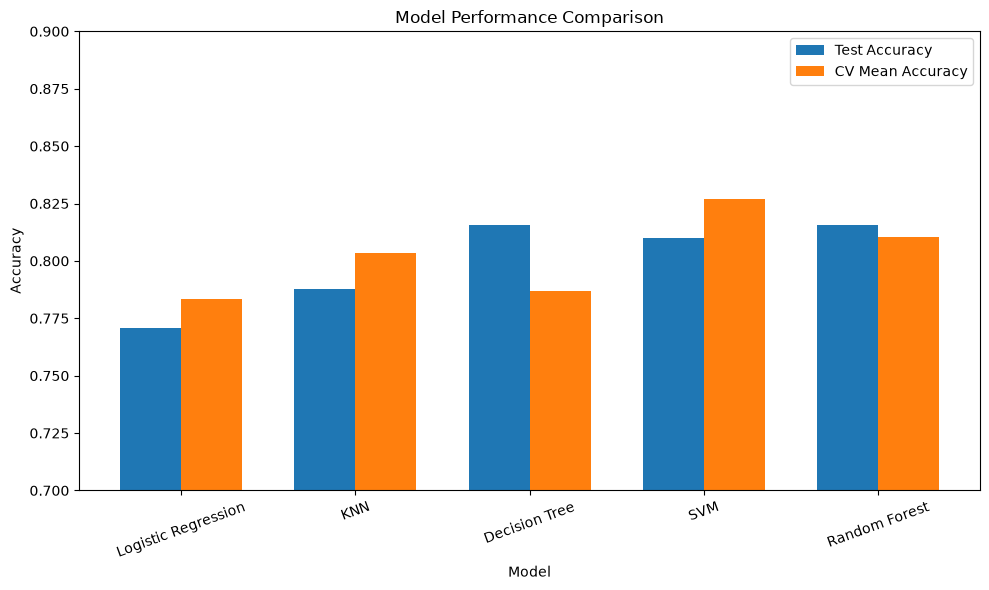

In [41]:
plt.figure(figsize=(10, 6))

x = np.arange(len(final_comparison["Model"]))
width = 0.35

plt.bar(
    x - width / 2,
    final_comparison["Test Accuracy"],
    width,
    label="Test Accuracy"
)

plt.bar(
    x + width / 2,
    final_comparison["CV Mean Accuracy"],
    width,
    label="CV Mean Accuracy"
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.xticks(
    x,
    final_comparison["Model"],
    rotation=20
)

plt.ylim(0.7, 0.9)

plt.legend()
plt.tight_layout()

plt.savefig(
    "images/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
cv_summary.to_csv(
    "images/cv_results.csv",
    index=False
)